# Notebook 01: Multi-Source Data Ingestion & Anti-Ban Web Crawling (Lecture 2 & Lecture 8)

**Project**: `TradeToiChet` — Multi-Source Financial Data Pipeline & VN30 Quantitative Trading Simulation  
**Package**: `src/ingestion/`  
**Course Alignment**:
- **Lecture 2 (Data Collection & Web Crawling)**: HTTP Request with User-Agent rotation, polite jitter delay, HTML DOM parsing via `BeautifulSoup4`, and Vietnamese financial sentiment scoring.
- **Lecture 8 (Big Data Storage)**: Columnar storage using Apache Parquet (`prices.parquet`, `news_sentiment.parquet`, `macro.parquet`) backed by persistent `SQLite` cache (`data/tradetoichet.db`).

In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# them thu muc goc vao sys.path de import src
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import DATA_RAW_DIR, SQLITE_DB_PATH, VN30_TICKERS
from src.ingestion import run_ingestion, run_news_crawler
from src.ingestion.db import get_connection

## 1. Run Incremental Data Ingestion & Web Crawling (SQLite Cache Hit Verification)

In [2]:
# chay pipeline: neu sqlite db da co du lieu thi se hit cache tuc thi (0 request mang)
run_ingestion()
run_news_crawler(max_pages=3)

[01/31] Cache hit in SQLite for ACB, skipping API call.
[02/31] Cache hit in SQLite for BCM, skipping API call.
[03/31] Cache hit in SQLite for BID, skipping API call.
[04/31] Cache hit in SQLite for BVH, skipping API call.
[05/31] Cache hit in SQLite for CTG, skipping API call.
[06/31] Cache hit in SQLite for FPT, skipping API call.
[07/31] Cache hit in SQLite for GAS, skipping API call.
[08/31] Cache hit in SQLite for GVR, skipping API call.
[09/31] Cache hit in SQLite for HDB, skipping API call.
[10/31] Cache hit in SQLite for HPG, skipping API call.
[11/31] Cache hit in SQLite for MBB, skipping API call.
[12/31] Cache hit in SQLite for MSN, skipping API call.
[13/31] Cache hit in SQLite for MWG, skipping API call.
[14/31] Cache hit in SQLite for PLX, skipping API call.
[15/31] Cache hit in SQLite for POW, skipping API call.
[16/31] Cache hit in SQLite for SAB, skipping API call.
[17/31] Cache hit in SQLite for SHB, skipping API call.
[18/31] Cache hit in SQLite for SSB, skipping AP

[25/31] Cache hit in SQLite for VIB, skipping API call.
[26/31] Cache hit in SQLite for VIC, skipping API call.
[27/31] Cache hit in SQLite for VJC, skipping API call.
[28/31] Cache hit in SQLite for VNM, skipping API call.
[29/31] Cache hit in SQLite for VPB, skipping API call.
[30/31] Cache hit in SQLite for VRE, skipping API call.
[31/31] Cache hit in SQLite for VNINDEX, skipping API call.


[OK] Saved 54,681 rows (31 tickers) to /home/kibito/Desktop/repos/TradeToiChet/data/raw/prices.parquet
[OK] Saved 1,751 rows of macro indicators to /home/kibito/Desktop/repos/TradeToiChet/data/raw/macro.parquet
[01/30] Cache hit in SQLite for ACB news, skipping crawl.
[02/30] Cache hit in SQLite for BCM news, skipping crawl.
[03/30] Cache hit in SQLite for BID news, skipping crawl.
[04/30] Cache hit in SQLite for BVH news, skipping crawl.
[05/30] Cache hit in SQLite for CTG news, skipping crawl.
[06/30] Cache hit in SQLite for FPT news, skipping crawl.
[07/30] Cache hit in SQLite for GAS news, skipping crawl.
[08/30] Cache hit in SQLite for GVR news, skipping crawl.
[09/30] Cache hit in SQLite for HDB news, skipping crawl.
[10/30] Cache hit in SQLite for HPG news, skipping crawl.
[11/30] Cache hit in SQLite for MBB news, skipping crawl.
[12/30] Cache hit in SQLite for MSN news, skipping crawl.
[13/30] Cache hit in SQLite for MWG news, skipping crawl.
[14/30] Cache hit in SQLite for PLX

## 2. Inspect Generated Raw Parquet Datasets & Verify Schema Contract

In [3]:
df_prices = pd.read_parquet(DATA_RAW_DIR / 'prices.parquet')
df_news = pd.read_parquet(DATA_RAW_DIR / 'news_sentiment.parquet')
df_macro = pd.read_parquet(DATA_RAW_DIR / 'macro.parquet')

print(f'1. prices.parquet shape        : {df_prices.shape} | unique tickers: {df_prices["ticker"].nunique()}')
print(f'2. news_sentiment.parquet shape: {df_news.shape} | unique tickers: {df_news["ticker"].nunique()}')
print(f'3. macro.parquet shape         : {df_macro.shape} | date range: {df_macro["date"].min().date()} -> {df_macro["date"].max().date()}')

df_prices.head(5)

1. prices.parquet shape        : (54681, 8) | unique tickers: 31


2. news_sentiment.parquet shape: (1847, 5) | unique tickers: 30
3. macro.parquet shape         : (1751, 6) | date range: 2019-01-02 -> 2026-02-27


,date,ticker,open,high,low,close,volume,sector
0,2019-01-02,ACB,5.66,5.66,5.53,5.58,1103106.0,Banking
1,2019-01-03,ACB,5.02,5.57,5.02,5.38,1956382.0,Banking
2,2019-01-04,ACB,5.35,5.45,5.27,5.41,2771983.0,Banking
3,2019-01-07,ACB,5.53,5.53,5.45,5.49,1305819.0,Banking
4,2019-01-08,ACB,6.00,6.00,5.45,5.45,846226.0,Banking


In [4]:
# xem mau tin tuc cafef da cao va diem cam xuc tieng viet
with get_connection(SQLITE_DB_PATH) as conn:
    df_raw_news = pd.read_sql_query('SELECT * FROM raw_news ORDER BY pub_date DESC LIMIT 15', conn)
df_raw_news

,ticker,pub_date,headline,sentiment_score
0,FPT,2026-11-22,FPT bốc hơi 23.000 tỷ đồng vốn hóa sau một thá...,-0.8283
1,VHM,2026-11-21,Vinhomes dự kiến huy động thêm 3.000 tỷ đồng t...,0.7957
2,BID,2026-11-20,BID: Nghị quyết HĐQT về việc phê duyệt một số ...,0.1918
3,BVH,2026-11-20,BVH: Báo cáo kết quả giao dịch cổ phiếu của tổ...,0.0311
4,FPT,2026-11-20,FPT tăng giá 9% với 55 khách hàng Nhật Bản khi...,0.8309
5,FPT,2026-11-20,Cổ phiếu,0.4067
6,HDB,2026-11-20,HDB: Nghị quyết HĐQT về việc lấy ý kiến cổ đôn...,0.1208
7,HDB,2026-11-20,HDB: Thông báo nhận được Quyết định của NHNN v...,0.0428
8,HDB,2026-11-20,HDB: Thông báo về việc thay đổi địa điểm và tê...,0.0215
9,MBB,2026-11-20,MBB: Báo cáo kết quả giao dịch cổ phiếu của tổ...,0.1323


## 3. Data Quality & Distribution Overview (OHLCV Count & News Sentiment Polarity)

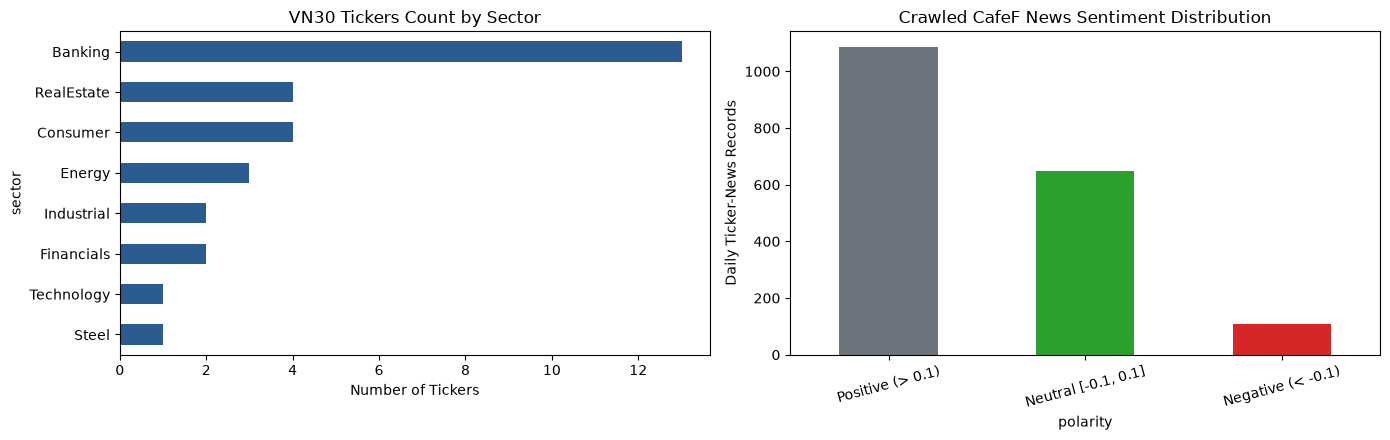

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# bieu do 1: so luong phien giao dich theo nhom nganh
sector_counts = df_prices[df_prices['ticker'] != 'VNINDEX'].groupby('sector')['ticker'].nunique().sort_values()
sector_counts.plot(kind='barh', ax=axes[0], color='#2b5c8f')
axes[0].set_title('VN30 Tickers Count by Sector')
axes[0].set_xlabel('Number of Tickers')

# bieu do 2: phan phoi diem cam xuc tin tuc cafef
df_news['polarity'] = df_news['sentiment_score'].apply(
    lambda s: 'Positive (> 0.1)' if s > 0.1 else ('Negative (< -0.1)' if s < -0.1 else 'Neutral [-0.1, 0.1]')
)
df_news['polarity'].value_counts().plot(kind='bar', ax=axes[1], color=['#6c757d', '#2ca02c', '#d62728'])
axes[1].set_title('Crawled CafeF News Sentiment Distribution')
axes[1].set_ylabel('Daily Ticker-News Records')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()